# 01 · Calidad del panel de onboarding

> **Demostración ficticia:** el modo predeterminado usa seis cuentas inventadas para ilustrar gráficos y controles. Cambia `MODO` a `plantilla` para leer tu archivo; la plantilla incluida no tiene observaciones. Nunca publiques información individual de clientes.

## Propósito
Antes de calcular vintage, comprobar que las observaciones por cuenta y MOB sean interpretables. La salida ayuda a identificar duplicados, nulos y faltantes; no certifica la calidad integral de la cartera.

## Contrato de entrada y controles

La unidad es `(corte_origen, loan_key, merchant_key, mob)`. Se exige un cliente por cuenta y cohorte; una misma cuenta no puede pertenecer a varias cohortes. MOB debe ser entero no negativo y DPD numérico no negativo. Los duplicados se rechazan, pues elegir una fila arbitraria alteraría el indicador.

Para un predictor en fecha $t_0$ se necesita $t_{disponibilidad} \le t_0$. El campo de disponibilidad es obligatorio solo si se solicita un corte `as_of`; su existencia no demuestra la trazabilidad de origen.

In [1]:
from pathlib import Path
import sys, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
base = Path.cwd()
if not (base / 'vintage_core.py').exists():
    root = next(p for p in [base, *base.parents] if (p / '03-financial-risk').is_dir())
    base = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(base))
from vintage_core import prepare_panel, build_vintage, summarize_vintage, GROUP
from demo_inputs import demo_panel
plt.rcParams.update({'figure.figsize':(10,4.8),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.2,'axes.axisbelow':True})
# Cambie a 'plantilla' para leer el CSV local; nunca cargue datos sensibles en Git.
MODO = 'demostracion'
assert MODO in ('demostracion', 'plantilla')
panel = demo_panel() if MODO == 'demostracion' else pd.read_csv(base/'plantilla_panel_mensual.csv')
print('MODO:',MODO.upper(),'— datos ficticios, no cartera real' if MODO=='demostracion' else '— plantilla o extracto del usuario')

MODO: DEMOSTRACION — datos ficticios, no cartera real


## 1. Calidad de llaves y valores

La tabla muestra cobertura de columnas y duplicados antes de activar el cálculo. `prepare_panel` falla ante errores de llaves o valores imposibles en lugar de corregirlos sin aviso.

In [2]:
required=['corte_origen','loan_key','merchant_key','client_id','mob','dpd','saldo_capital_cop']
missing_columns=[c for c in required if c not in panel.columns]
print('Filas:',len(panel),'| columnas requeridas ausentes:',missing_columns)
if not missing_columns and not panel.empty:
    print('Filas duplicadas por cuenta–MOB:',int(panel.duplicated(GROUP+['mob'],keep=False).sum()))
    display(pd.DataFrame({'observados':panel[required].notna().sum(),'nulos':panel[required].isna().sum()}))
    clean=prepare_panel(panel)
else:
    clean=panel.copy();print('Sin observaciones; no se calcula calidad de cartera.')

Filas: 18 | columnas requeridas ausentes: []
Filas duplicadas por cuenta–MOB: 0


,observados,nulos
corte_origen,18,0
loan_key,18,0
merchant_key,18,0
client_id,18,0
mob,18,0
dpd,17,1
saldo_capital_cop,17,1


## 2. Maduración y saldo

Una cuenta se considera evaluable para MOB 3 si tiene DPD observado en cada uno de los meses 1, 2 y 3. La fecha y la convención de MOB deben ser revisadas con negocio. El saldo de capital a MOB 3 es válido si es finito y no negativo; la elegibilidad para número y para dinero se reporta por separado.

Cuentas representadas: 6 | evaluables: 5 | con saldo válido: 4


,corte_origen,loan_key,eligible,missing_mobs,balance_valid
0,2024-01,A,True,,True
1,2024-01,B,True,,True
2,2024-01,C,False,2,False
3,2024-02,D,True,,True
4,2024-02,E,True,,True
5,2024-02,F,True,,False


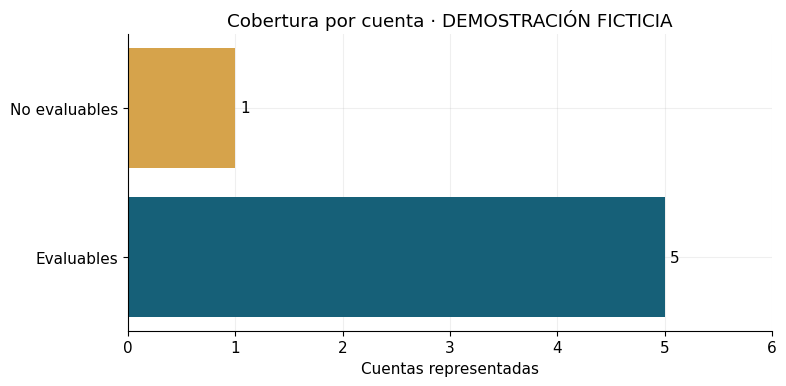

In [3]:
accounts,clients=build_vintage(clean,3)
if not accounts.empty:
    print('Cuentas representadas:',len(accounts),'| evaluables:',int(accounts.eligible.sum()),'| con saldo válido:',int(accounts.balance_valid.sum()))
    display(accounts[['corte_origen','loan_key','eligible','missing_mobs','balance_valid']])
    status=pd.Series({'Evaluables':int(accounts.eligible.sum()),'No evaluables':int((~accounts.eligible).sum())})
    fig,ax=plt.subplots(figsize=(8,4));ax.barh(status.index,status.values,color=['#166078','#d6a34b']);ax.set(xlabel='Cuentas representadas',title='Cobertura por cuenta · DEMOSTRACIÓN FICTICIA' if MODO=='demostracion' else 'Cobertura por cuenta');ax.set_xlim(0,max(status.max()*1.2,1));
    for i,v in enumerate(status.values): ax.text(v+0.05,i,str(v),va='center')
    plt.tight_layout();plt.show()
else: print('Sin cuentas: cargar el panel para ver resultados.')

## 3. Conciliación previa al uso

- Cruzar con originación por las llaves y la fecha de disponibilidad, reportando cuentas sin panel y panel sin originación.
- Comparar totales, producto y saldo con contabilidad; registrar cancelaciones, castigos y migraciones.
- Verificar consistencia entre MOB y fechas, cambios de cliente y retrasos de publicación.
- El motor no supone que una cuenta cerrada o ausente esté al día; se mantiene como no evaluable.

## Alcance y control de uso

La salida de demostración es ficticia y no valida desempeño de originación. Conciliar el panel con el universo de originación: una cuenta ausente por completo del panel, o descartada por un corte `as_of`, no aparece en el denominador. Un indicador mensual tampoco detecta necesariamente una mora intrames. Las reglas de población, DPD >30, MOB, saldos, cierres y castigos requieren aprobación institucional.